<table>
    <tr>
        <td style="text-align:left">
            <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR9ItLTT_F-3Q30cu7ZCCoKmuFGBt22pe7pNA" alt="Logo Universidad" width="300"/>
        </td>
        <td>
            Departamento de Ciencias de la Computación y de la Decisión<br>
            Facultad de Minas<br>
            Universidad Nacional de Colombia<br>
            Optimizacion e IA 2026-2S<br><br>
            Docente: Maria Constanza Torres Madronero<br>
            <br>
            Contribuciones a la guia por: <br>
            - Deimer Miranda Montoya (2023)<br>
            - Luis Fernando Becerra Monsalve (2024)
        </td>    
    </tr>
</table>

# **Perceptron Multicapa usando Keras para Regresion**





Usaremos la **API Secuencial de Keras**, una interfaz de alto nivel provista por TensorFlow que permite construir modelos de manera muy intuitiva. Gracias a esta API, podemos:

- **Definir la arquitectura de la red** en unas pocas líneas de código.
- **Compilar y entrenar el modelo** de forma eficiente.
- **Evaluar el desempeño del modelo** con funciones predefinidas.
- **Visualizar resultados** fácilmente con herramientas como Matplotlibc

El standard scaler funciona muy bien cuando las features se distribuyen aproximadamente normal porque ya de por si es un escalador muy sensible a los outliers. La mejor practica seria primero mirar la distribucion de frecuencias de cada features y ya luego decidir si efectivamente tienen una disitribucion aproximadamente normal, o sino antes de eso aplicarle alguna transformacion que las haga normal

Por otro lado el robust scaler es una variacion que se usa particularmente cuando la feature tiene muchos outliers porque hace el escalamiento a partir de la mediana (que se considera como un estadistico insesgado a diferencia de la media) y el rango interquartil. Entonces no se digamos que por ejemplo la feature es la cantidad de plata que una persona gasta. Una feature de esas puede estar tipicamente sesgada porque podemos tener gente que gaste muchisimo, y por otro lado gente que gasta poquito entonces aca el Robust Scaler puede funcionar mejor

Otra cosa que suele funcionar bien es aplicar logaritmo en casos de que la features este sesgada hacia un valor muy extremo ya que el logaritmo lo que hace en esos casos es convertir a una distribucion aproximadamente normal. Y ya una vez con esa distribucion si podriamos aplicar standard scaler

In [ ]:
#Importacion de librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
###
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import metrics


In [2]:
import tensorflow as tf
from tensorflow import keras

In [3]:
#Carga de datos con los precios de vivienda de California
housing = fetch_california_housing()

#Organizacion de los conjuntos de entrenamiento, validacion y prueba
# Es recomendable hacer un conjunto de Validación 

x_train, x_test, y_train, y_test = train_test_split(housing.data, housing.target, test_size=0.3)
x_train, x_valid, y_train, y_valid = train_test_split(x_train, y_train, test_size=0.1)

In [8]:
x_train.data.shape

(13003, 8)

In [6]:
housing.target

array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,))

In [4]:
#Exploracion de los datos
print("Datos de entrenamiento: ", x_train.shape)
print("Datos de prueba: ", x_test.shape)
print("Datos de validacion: ", x_valid.shape)
print("Tipo de dato: ", x_train.dtype)
print("Ejemplo de datos:", x_train[1,:])

Datos de entrenamiento:  (13003, 8)
Datos de prueba:  (6192, 8)
Datos de validacion:  (1445, 8)
Tipo de dato:  float64
Ejemplo de datos: [   4.5893       45.            5.40061162    1.01529052  869.
    2.65749235   37.78       -122.2       ]


In [ ]:
#Normalizacion de los datos
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train) 

# con el escalor entrenado se transforman los de validación y prueba. 
# Con el promedio y la desviación estandar de los datos de entrenamiento se normalizan los datos de validación y prueba.
# se usan en medidas física, o si son numeros negativos 
# max_min scaler son normalmente cuando los datos son positivos y tienen una escala definida, por ejemplo, cuando se tienen datos de imagenes.
# o se tienen datos que están de 0 a 255, etc
x_valid = scaler.transform(x_valid)
x_test = scaler.transform(x_test)
print("Datos de entrenamiento normalizados: ", x_train[1,:])

Datos de entrenamiento normalizados:  [ 0.38666034  1.30258605 -0.01558121 -0.17876787 -0.48368127 -0.05424136
  1.01382787 -1.31911704]


In [6]:
x_train.shape

(13003, 8)

Ahora, vamos a construir la red neuronal multicapa (MLP) empleando el modelo Sequential API de Keras. La principal diferencia con la NN de clasificacion es la capa de salida, que incluye solo una neurona y no se usa funcion de activacion.






In [ ]:
#Construccion del MLP
neuronas_entrada = x_train.shape[1:]

model = keras.models.Sequential([
    #Vamos a incluir dos capas
    keras.layers.Dense(30, activation="relu", input_shape=neuronas_entrada), # 8 neuronas de entrada porque son 8 caracteristicas de entrada y 30 neuronas en la capa oculta
    keras.layers.Dense(1)
])


c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\keras\src\layers\core\dense.py:102: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#Vamos a revisar el modelo
# Parametros = 8*30 + 30 = 270 --> 8 neuronas de entrada * 30 neuronas en la capa oculta + 30 neuronas en la capa oculta (bias)
# Parametros = 30*1 + 1 = 31 --> 30 neuronas de la capa oculta * 1 neurona de salida + 1 neurona de salida (bias)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 30)             │           270 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            31 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 301 (1.18 KB)

 Trainable params: 301 (1.18 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Podemos acceder a la lista de capas o nombres:
model.layers

[<Dense name=dense, built=True>, <Dense name=dense_1, built=True>]

In [ ]:
#Revisar los pesos y bias de cada capa
hidden1 = model.layers[0]
print(hidden1.name)
weights, biases = hidden1.get_weights()

#Mostrar los pesos que no son entrenados, son inicializados aleatoriamente:
# antes se inicilizaban en 0, pero así nunca se podía entrenar la red, porque todos los pesos eran iguales y no se podía aprender nada.
weights

dense


array([[-0.19643304,  0.22075179,  0.29243055, -0.3065802 , -0.14632493,
         0.23131469,  0.37746957, -0.22313437,  0.37565807,  0.30482385,
         0.07074982,  0.23825565, -0.26871827, -0.18728468, -0.00440454,
        -0.27436864,  0.39116707, -0.2060496 , -0.26829934,  0.2678822 ,
        -0.21392271, -0.34310412, -0.20302482, -0.00745237,  0.13479683,
         0.19188628, -0.16216747, -0.31838822,  0.07276461,  0.20468035],
       [ 0.22326341, -0.1990714 ,  0.372327  , -0.22478697, -0.18283711,
         0.2050986 , -0.05904806,  0.08411932, -0.10925964,  0.18364486,
        -0.04345933,  0.38365427,  0.08187661, -0.24380732,  0.10534027,
        -0.28529847,  0.08451146, -0.3184646 ,  0.29452488, -0.0078803 ,
         0.2729936 , -0.1197696 , -0.1604692 , -0.30404538, -0.17175835,
        -0.2660913 , -0.31492737,  0.12209162, -0.22028331, -0.39331514],
       [-0.2257947 , -0.11478996, -0.03197774,  0.2827004 ,  0.03362381,
        -0.32128257,  0.24290094,  0.1364139 ,  0

In [ ]:
#Mostrar biases, cuando se entrene ya no serán 0
biases

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [12]:
#Vamos a compilar el modelo
model.compile(loss="mean_squared_error", optimizer="sgd")

In [ ]:
#Una vez compilado, esta listo para ser entrenado
#a traves del metodo fit
#Le enviamos los datos de entrenamiento, el numero
#de epocas, y el set de validacion (opcional)
history = model.fit(x_train, y_train, epochs=20, validation_data=(x_valid, y_valid))

# loss: datos de entrenamiento --> la definida: el error cuadratico medio
# val_loss: datos de validacion --> el error cuadratico medio en los datos de validacion

Epoch 1/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1.4713 - val_loss: 0.6046
Epoch 2/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4589 - val_loss: 0.4359
Epoch 3/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4061 - val_loss: 0.4099
Epoch 4/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3882 - val_loss: 0.3960
Epoch 5/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3768 - val_loss: 0.3886
Epoch 6/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3700 - val_loss: 0.3844
Epoch 7/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3662 - val_loss: 0.3802
Epoch 8/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3644 - val_loss: 0.3789
Epoch 9/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3602 - val_loss: 0.3749
Epoch 10/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3552 - val_loss: 0.3729
Epoch 11/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3525 - val_loss: 0.3701
Epoch 12/20
407/407 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

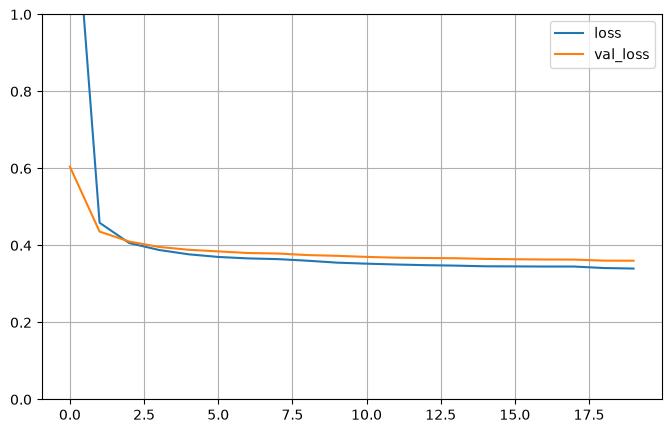

In [14]:
#Grafica de curva de aprendizaje
pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1) # set the vertical range to [0-1]
plt.show()

Una vez el modelo es entrenado, podemos pasar a la evaluación del mismo. Si no está satisfecho con los resultados, puede explorar la modificación de algunos hiperparametros, tales como el número de capas ocultas, el numero de neuronas, el paso de aprendizaje, entre otros.

In [15]:
#Evaluacion del modelo
y_pred=model.predict(x_test)
print("MAE: ", metrics.mean_absolute_error(y_test,y_pred))
print("MSE: ", metrics.mean_squared_error(y_test,y_pred))
print("R2:  ", metrics.r2_score(y_test,y_pred))

194/194 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
MAE:  0.40437072023145293
MSE:  0.340804409028596
R2:   0.745584209219613


Dependiendo la complejidad del modelo, su entrenamiento puede tomar mas tiempo. Por lo cual, es conveniente almacenar el modelo entrenado. Para ello pueden hacer uso de la instruccion:
>>model.save("my_keras_model.h5")
Para volver a cargar el modelo, pueden usar la instruccion:
>>model = keras.models.load_model("my_keras_model.h5")

In [ ]:
weights, biases = hidden1.get_weights() # ---> Modelo aprendido, los pesos y bias ya no son 0, ahora son valores que permiten hacer predicciones correctas.

In [18]:
biases

array([-0.34846598,  0.3879067 ,  0.39995843, -0.05796844, -0.1691363 ,
       -0.27862406, -0.13597281, -0.2864626 ,  0.21808793,  0.35420546,
       -0.20600747, -0.3743863 , -0.05620966,  0.4041263 , -0.22371218,
        0.04792365,  0.08499883, -0.0455247 ,  0.23142491, -0.26355183,
        0.04750815,  0.13630095,  0.3367922 , -0.05188987,  0.1321457 ,
       -0.17782673,  0.3786221 , -0.14432986,  0.23992805, -0.00799071],
      dtype=float32)

In [19]:
weights

array([[-3.88827980e-01,  1.78070739e-01,  5.70244312e-01,
        -2.83051968e-01, -9.30858105e-02,  4.05483484e-01,
         1.11295372e-01, -2.28170246e-01,  3.83016229e-01,
         4.69849885e-01,  3.74548249e-02,  2.89448351e-01,
        -2.77410001e-01, -3.05279434e-01,  1.04483239e-01,
        -2.66647220e-01,  4.16112959e-01, -1.72674626e-01,
         8.12805295e-02,  2.84520268e-01, -2.41264746e-01,
        -1.90794200e-01, -2.14589119e-01, -5.49714342e-02,
         1.90961957e-02,  4.03629839e-01, -1.65276434e-02,
        -1.02560163e-01, -1.83890406e-02,  3.04582924e-01],
       [ 7.26234317e-02, -1.83569685e-01,  2.82924324e-01,
        -2.25824103e-01, -2.59124804e-02,  1.25770688e-01,
         9.02132615e-02, -2.29166448e-02, -1.78219862e-02,
         1.08398914e-01,  1.52062640e-01,  2.16909841e-01,
         1.60866603e-01, -5.77588789e-02,  2.32468382e-01,
        -3.03791314e-01,  9.23090950e-02, -3.58141214e-01,
         3.53497379e-02,  1.48204835e-02,  3.22402477e-